# White-box attacks: ASR and cross-model transfer statistics

Transfer matrices for GCG and BEAST: rows are the model the adversarial suffix was optimised on (*suffix source*), columns are the model it is evaluated on (*evaluation model*). Each model appears twice — as the baseline (`BASE`) and with the SAE inserted (`SAE`).

The matrix is split into four quadrants — `BASE → BASE` (BB), `SAE → SAE` (SS), `BASE → SAE` (BS) and `SAE → BASE` (SB) — and compared with two-sided Mann–Whitney U tests and bootstrap 95% CIs for the median (paper, Tables 1–2). The last cell draws the stacked GCG/BEAST bar chart (paper, Figure 1).

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


data_gcg = {
    "Gemma 2 2B BASE": [
        60.0, 12.5, 7.5, 5.0, 5.0, 5.0, 9.6, 11.5, 5.0, 7.3, 7.3, 5.0
    ],
    "Gemma 2 9B BASE": [
        12.5, 80.0, 15.0, 7.5, 5.0, 2.5, 4.1, 31.2, 7.8, 7.8, 9.6, 12.5
    ],
    "Gemma 2 27B BASE": [
        25.0, 60.0, 77.5, 15.0, 30.0, 17.5, 11.5, 24.3, 27.1, 13.8, 25.0, 37.5
    ],
    "Llama 3.1 8B INS BASE": [
        15.0, 17.5, 5.0, 47.5, 12.5, 5.0, 11.0, 11.0, 11.5, 26.1, 17.9, 15.0
    ],
   "Llama 3.1 70B INS BASE": [
       5.0, 7.5, 7.5, 15.0, 27.5, 10.0, 21.6, 23.4, 23.9, 25.7, 42.7, 12.5
    ],
    "Mistral 7B BASE": [
        5.0, 32.5, 7.5, 12.5, 2.5, 50.0, 5.0, 17.0, 12.8, 8.7, 18.8, 15.0
    ],
    "Gemma 2 2B SAE": [
        7.5, 0.0, 2.9, 2.1, 7.5, 2.7, 23.9, 1.5, 1.1, 1.4, 2.3, 8.1
    ],
    "Gemma 2 9B SAE": [
        0.0, 10.0, 0.0, 0.0, 0.0, 0.0, 0.0, 38.1, 0.0, 0.0, 0.5, 0.0
    ],
    "Gemma 2 27B SAE": [
        12.5, 40.0, 40.0, 7.5, 15.0, 12.5, 6.5, 23.4, 41.5, 8.3, 17.5, 17.5
    ],
    "Llama 3.1 8B INS SAE": [
        12.5, 15.0, 10.0, 22.5, 17.5, 2.5, 11.9, 13.8, 13.8, 14.2, 19.7, 10.0
    ],
   "Llama 3.1 70B INS SAE": [
       0.0, 0.0, 2.5, 0.0, 10.0, 0.0, 0.0, 0.0, 0.0, 0.0, 5.5, 2.5
   ],
    "Mistral 7B SAE": [
        7.5, 25.0, 2.5, 7.5, 7.5, 7.5, 1.8, 8.3, 4.1, 2.8, 4.1, 10.0
    ],
}

index_gcg = [
    "Gemma 2 2B BASE",
    "Gemma 2 9B BASE",
    "Gemma 2 27B BASE",
    "Llama 3.1 8B INS BASE",
    "Llama 3.1 70B INS BASE",
    "Mistral 7B BASE",
    "Gemma 2 2B SAE",
    "Gemma 2 9B SAE",
    "Gemma 2 27B SAE",
    "Llama 3.1 8B INS SAE",
    "Llama 3.1 70B INS SAE",
    "Mistral 7B SAE",
]

df = pd.DataFrame(data_gcg, index=index_gcg)

In [49]:
df.shape

(12, 12)

In [50]:
base_models = [i for i in df.columns.tolist() if 'base' in i.lower()]
sae_models = [i for i in df.columns.tolist() if 'sae' in i.lower()]

In [51]:
df.loc[sae_models, sae_models].values.diagonal() 

#[array([60. , 80. , 77.5, 47.5, 50. ]) # GCG ASRs on base models (27.5 excluded)
# array([23.9, 38.1, 41.5, 14.2,  10. ]) # GCG ASRs on SAE models (5.5 excluded) 

#[array([13.8 , 16.2 , 31.2, 12.4, 26.0]) # BEAST ASRs on base models 
# array([6.6, 0.0, 16.0, 17.0,  8.8]) # BEAST ASRs on SAE models

array([23.9, 38.1, 41.5, 14.2,  5.5, 10. ])

In [52]:
# split data to matricies
BB_gcg = df.loc[base_models, base_models]  # BASE → BASE
SB_gcg = df.loc[sae_models, base_models]   # SAE  → BASE
BS_gcg = df.loc[base_models, sae_models]   # BASE → SAE
SS_gcg = df.loc[sae_models, sae_models]    # SAE  → SAE


def drop_diag_and_flatten(matrix):
    """Drop main diag (to base-base and sae-sae models)"""
    arr = matrix.values.astype(float)
    if arr.shape[0] == arr.shape[1]:  
        mask = ~np.eye(arr.shape[0], dtype=bool)
        arr = arr[mask]
    else:
        arr = arr.flatten()
    return arr


def bootstrap_CI(data, n_boot=5000, ci=95):
    """bootstrap_CI for median"""
    data = np.array(data)
    boot = []
    for _ in range(n_boot):
        sample = np.random.choice(data, size=len(data), replace=True)
        boot.append(np.median(sample))
    alpha = (100 - ci) / 2
    return np.percentile(boot, [alpha, 100 - alpha])


def analyze(name, matrix, drop_diag=True):

    if drop_diag:
        values = drop_diag_and_flatten(matrix)
    else:
        values = matrix.values.flatten()
    median = np.median(values)
    lb, ub = bootstrap_CI(values)

    print(f"\n{name}:")
    print(f"  Median: {median:.3f}")
    print(f"  95% CI: [{lb:.3f}, {ub:.3f}]")
    print(f"  N={len(values)}")



analyze("BASE → BASE", BB_gcg)
print("Base modesl median ASR", np.median(BB_gcg.values.diagonal()))
analyze("SAE → SAE", SS_gcg)
print("SAE modesl median ASR", np.median(SS_gcg.values.diagonal()))


analyze("SAE → BASE", SB_gcg, drop_diag=False)
analyze("BASE → SAE", BS_gcg, drop_diag=False)


BASE → BASE:
  Median: 8.750
  95% CI: [6.250, 13.750]
  N=30
Base modesl median ASR 55.0

SAE → SAE:
  Median: 2.650
  95% CI: [1.250, 8.200]
  N=30
SAE modesl median ASR 19.049999999999997

SAE → BASE:
  Median: 12.650
  95% CI: [11.000, 17.900]
  N=36

BASE → SAE:
  Median: 7.500
  95% CI: [2.500, 10.000]
  N=36


In [53]:
from scipy.stats import mannwhitneyu

def mw_test(name1, x, name2, y, drop_diag=False):
    if drop_diag:
        x = drop_diag_and_flatten(x)
        y = drop_diag_and_flatten(y)
    else:
        x = x.values.flatten()
        y = y.values.flatten()

    u, p = mannwhitneyu(x, y, alternative="two-sided")
    
    print(f"{name1} vs {name2}")
    print(f"  n1={len(x)}, n2={len(y)}")
    print(f"  median1={np.median(x):.3f}, median2={np.median(y):.3f}")
    print(f"  U={u}, p={p}")
    if p < 0.05:
        print('Significant')
    print()


mw_test("BB", BB_gcg, "SS", SS_gcg, drop_diag=True) # check that the SAE median is lower

mw_test("BS", BS_gcg, "SB", SB_gcg) # asymmetry: base -> SAE vs. SAE -> base 

BB vs SS
  n1=30, n2=30
  median1=8.750, median2=2.650
  U=664.5, p=0.001504325215709217
Significant

BS vs SB
  n1=36, n2=36
  median1=7.500, median2=12.650
  U=316.5, p=0.00018695116022780193
Significant



In [56]:
u, p = mannwhitneyu(BB_gcg.values.diagonal(), SS_gcg.values.diagonal(), alternative="two-sided")
print(p < 0.05)
print(p)

print('GCG BB diags:', BB_gcg.values.diagonal())
print('GCG SS diags:', SS_gcg.values.diagonal())

True
0.008658008658008658
GCG BB diags: [60.  80.  77.5 47.5 27.5 50. ]
GCG SS diags: [23.9 38.1 41.5 14.2  5.5 10. ]


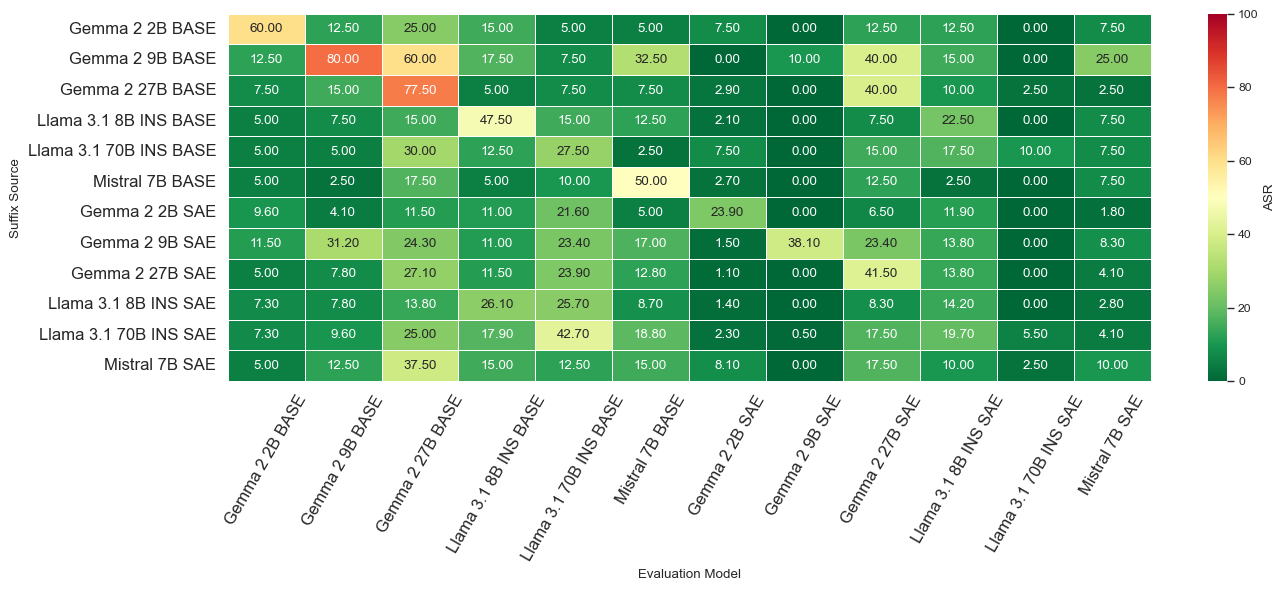

In [57]:
import seaborn as sns 


df01 = df.astype(float) 

sns.set_theme(style="white", context="paper")

plt.figure(figsize=(14, 6))
ax = sns.heatmap(
    df01,
    vmin=0, vmax=100,
    cmap="RdYlGn_r",          
    annot=True, fmt=".2f",
    linewidths=0.5, linecolor="white",
    cbar_kws={"label": "ASR"}
)


ax.set_xlabel("Evaluation Model")
ax.set_ylabel("Suffix Source")
ax.set_xticklabels(ax.get_xticklabels(), rotation=60, ha="center", fontsize=12)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=12)

plt.tight_layout()
plt.show()

In [58]:
import pandas as pd
import numpy as np

# Model order (same for rows and columns)
base_models = [
    "Gemma 2B BASE", "Gemma 9B BASE", "Gemma 27B BASE",
    "Llama 8B BASE", "Llama 70B BASE", "Mistral 7B BASE"
]
sae_models = [
    "Gemma 2B SAE", "Gemma 9B SAE", "Gemma 27B SAE",
    "Llama 8B SAE", "Llama 70B SAE", "Mistral 7B SAE"
]
models = base_models + sae_models

# Raw quadrant data (BEAST), transcribed from the per-model evaluation runs
# q1: BASE -> BASE
q1 = np.array([
    [13.8, 16.3, 28.1, 11.5, 22.0, 32.9],
    [ 7.0, 16.2, 20.5, 11.9, 20.2, 13.8],
    [11.8, 18.9, 31.2, 12.4, 17.0, 21.8],
    [ 4.6,  7.5, 14.6, 12.4, 24.3, 15.9],
    [ 0.0,  0.0,  0.0,  7.8, 22.5, 18.0],
    [ 9.6, 22.9, 28.0, 13.3, 19.7, 26.0],
])

# q2: BASE -> SAE
q2 = np.array([
    [4.5, 0.5, 22.1, 13.3,  9.6, 15.2],
    [1.1, 0.0, 19.2, 12.4,  8.7,  5.2],
    [3.0, 0.5, 19.0, 13.3,  6.9,  7.4],
    [1.1, 0.0,  7.7, 12.8, 11.0,  6.1],
    [5.1, 0.0, 14.8, 13.8,  9.6,  6.7],
    [1.9, 0.5, 23.5, 19.7,  9.2, 10.7],
])

# q3: SAE -> BASE
q3 = np.array([
    [20.7, 24.5, 31.7, 14.7, 22.5, 27.3],
    [ 5.8,  9.4,  7.0, 11.9, 21.6, 10.1],
    [ 7.9,  8.0, 19.2, 11.9, 19.3, 15.4],
    [ 1.7,  6.6,  8.3, 13.8, 20.6,  8.7],
    [ 0.0,  0.0,  0.0, 10.8, 22.5, 14.1],
    [ 6.3, 10.8, 16.3, 11.0, 21.6, 19.8],
])

# q4: SAE -> SAE
q4 = np.array([
    [6.6, 0.0, 21.0, 16.5,  9.6, 10.4],
    [2.7, 0.0,  9.8, 11.5,  7.3,  4.2],
    [3.1, 0.0, 16.0, 16.5,  6.0,  8.7],
    [0.0, 0.6,  3.5, 17.0,  7.3,  2.3],
    [0.0, 0.0,  4.7, 18.1, 10.6,  3.2],
    [3.3, 1.4, 14.7, 15.6,  6.4,  8.8],
])

# Assemble full 12x12
top = np.concatenate([q1, q2], axis=1)
bot = np.concatenate([q3, q4], axis=1)
full = np.concatenate([top, bot], axis=0)

df_beast = pd.DataFrame(full, index=models, columns=models)

base_models = [i for i in df_beast.columns.tolist() if 'base' in i.lower()]
sae_models = [i for i in df_beast.columns.tolist() if 'sae' in i.lower()]

In [59]:
# split data to matricies
BB = df_beast.loc[base_models, base_models]  # BASE → BASE
SB = df_beast.loc[sae_models, base_models]   # SAE  → BASE
BS = df_beast.loc[base_models, sae_models]   # BASE → SAE
SS = df_beast.loc[sae_models, sae_models]    # SAE  → SAE


def drop_diag_and_flatten(matrix):
    """Drop main diag (to base-base and sae-sae models)"""
    arr = matrix.values.astype(float)
    if arr.shape[0] == arr.shape[1]:  
        mask = ~np.eye(arr.shape[0], dtype=bool)
        arr = arr[mask]
    else:
        arr = arr.flatten()
    return arr


def bootstrap_CI(data, n_boot=5000, ci=95):
    """bootstrap_CI for median"""
    data = np.array(data)
    boot = []
    for _ in range(n_boot):
        sample = np.random.choice(data, size=len(data), replace=True)
        boot.append(np.median(sample))
    alpha = (100 - ci) / 2
    return np.percentile(boot, [alpha, 100 - alpha])



analyze("BASE → BASE", BB)
print("Base modesl median ASR", np.median(BB.values.diagonal()))
analyze("SAE → SAE", SS)
print("SAE modesl median ASR", np.median(SS.values.diagonal()))


analyze("SAE → BASE", SB, drop_diag=False)
analyze("BASE → SAE", BS, drop_diag=False)


BASE → BASE:
  Median: 15.250
  95% CI: [11.850, 19.300]
  N=30
Base modesl median ASR 19.35

SAE → SAE:
  Median: 5.350
  95% CI: [3.150, 9.150]
  N=30
SAE modesl median ASR 9.7

SAE → BASE:
  Median: 11.900
  95% CI: [9.400, 16.950]
  N=36

BASE → SAE:
  Median: 8.200
  95% CI: [5.200, 11.000]
  N=36


In [60]:
mw_test("BB", BB, "SS", SS, drop_diag=True) # check that the SAE median is lower
mw_test("BS", BS, "SB", SB) # asymmetry: base -> SAE vs. SAE -> base 

BB vs SS
  n1=30, n2=30
  median1=15.250, median2=5.350
  U=698.5, p=0.00024157657777541558
Significant

BS vs SB
  n1=36, n2=36
  median1=8.200, median2=11.900
  U=432.5, p=0.015419805084522498
Significant



In [61]:
u, p = mannwhitneyu(BB.values.diagonal(), SS.values.diagonal(), alternative="two-sided")
print(p < 0.05)
print(p)

print('BEAST BB diags:', BB.values.diagonal())
print('BEAST SS diags:', SS.values.diagonal())

True
0.04112554112554113
BEAST BB diags: [13.8 16.2 31.2 12.4 22.5 26. ]
BEAST SS diags: [ 6.6  0.  16.  17.  10.6  8.8]


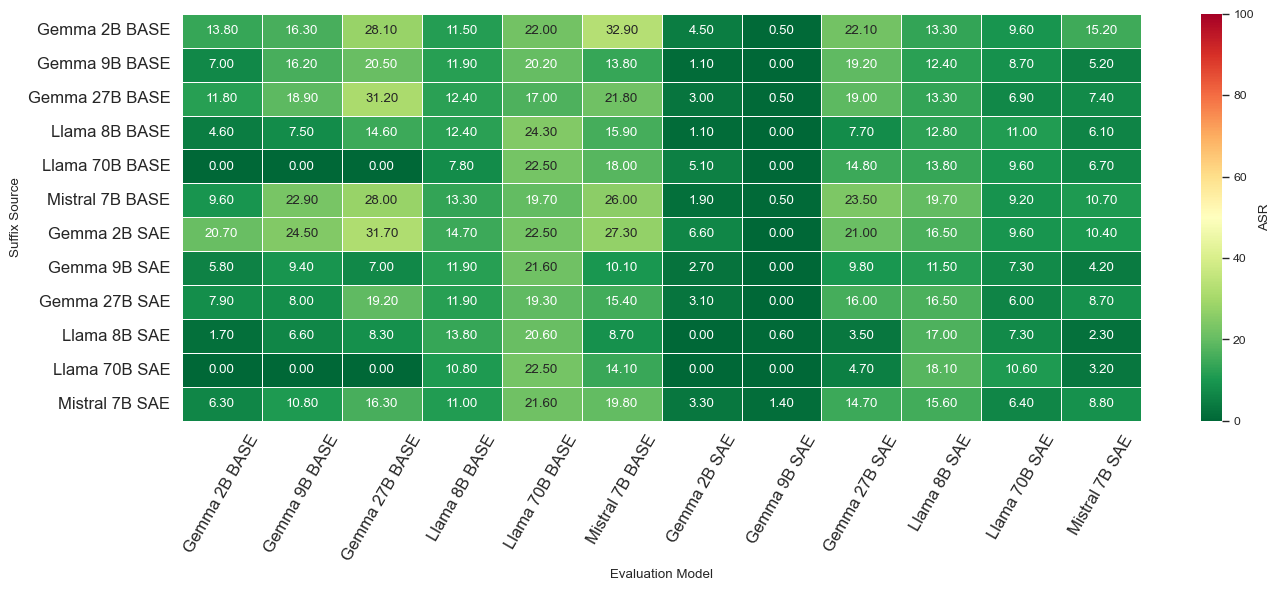

In [14]:
sns.set_theme(style="white", context="paper")

plt.figure(figsize=(14, 6))
ax = sns.heatmap(
    df_beast,
    vmin=0, vmax=100,
    cmap="RdYlGn_r",          
    annot=True, fmt=".2f",
    linewidths=0.5, linecolor="white",
    cbar_kws={"label": "ASR"}
)


ax.set_xlabel("Evaluation Model")
ax.set_ylabel("Suffix Source")
ax.set_xticklabels(ax.get_xticklabels(), rotation=60, ha="center", fontsize=12)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=12)

plt.tight_layout()
plt.show()

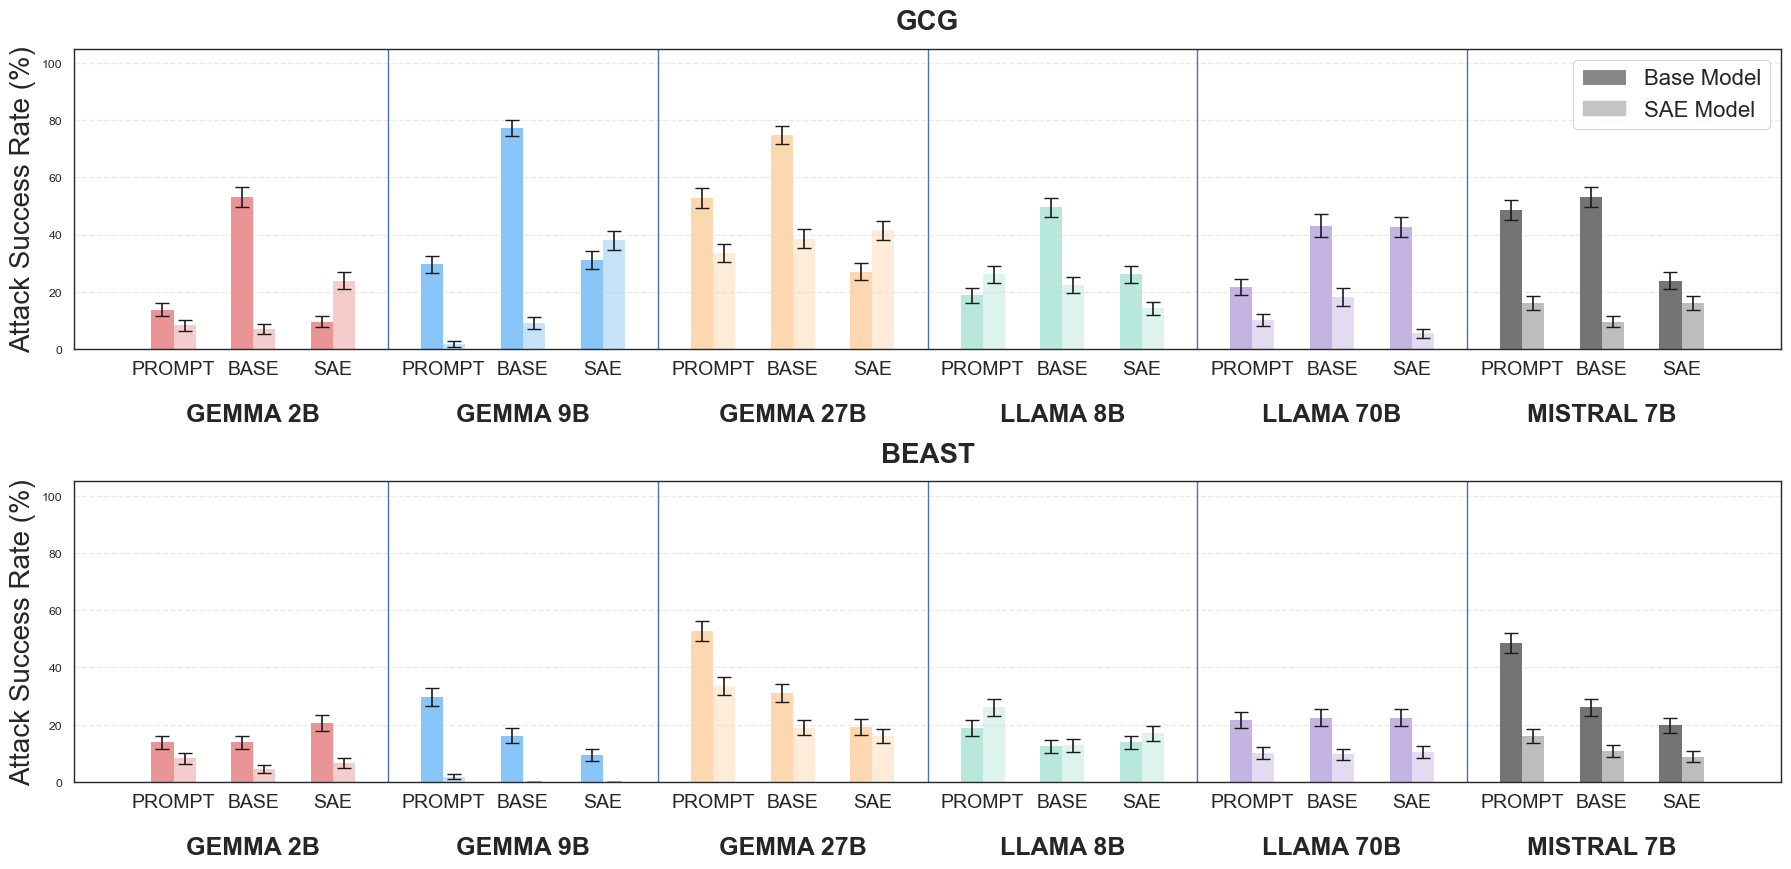

In [86]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Models (order must match across GCG + BEAST)
# -----------------------------
models = ["GEMMA 2B", "GEMMA 9B", "GEMMA 27B", "LLAMA 8B", "LLAMA 70B", "MISTRAL 7B"]
cats = ["PROMPT", "BASE", "SAE"]  # x-axis categories within each model group

# -----------------------------
# GCG (means ± SEM) from your Table (Base ASR and SAE ASR columns)
# Format per model: dict(cat -> (base_mean, sae_mean, base_sem, sae_sem))
# -----------------------------
gcg = {
    "GEMMA 2B": {
        "PROMPT": (13.8,  8.3, 2.3, 1.9),
        "BASE":   (53.2,  7.1, 3.4, 1.8),
        "SAE":    ( 9.6, 23.9, 2.0, 2.9),
    },
    "GEMMA 9B": {
        "PROMPT": (29.6,  1.8, 3.1, 0.9),
        "BASE":   (77.3,  9.2, 2.9, 2.0),
        "SAE":    (31.2, 38.1, 3.1, 3.3),
    },
    "GEMMA 27B": {
        "PROMPT": (52.8, 33.5, 3.4, 3.2),
        "BASE":   (74.8, 38.5, 3.0, 3.3),
        "SAE":    (27.1, 41.5, 3.0, 3.4),
    },
    "LLAMA 8B": {
        "PROMPT": (18.8, 26.1, 2.7, 3.0),
        "BASE":   (49.5, 22.5, 3.4, 2.8),
        "SAE":    (26.1, 14.2, 3.0, 2.4),
    },
    "LLAMA 70B": {
        "PROMPT": (21.6, 10.1, 2.8, 2.0),
        "BASE":   (43.1, 18.1, 4.1, 3.2),
        "SAE":    (42.7,  5.5, 3.4, 1.6),
    },
    "MISTRAL 7B": {
        "PROMPT": (48.6, 16.1, 3.4, 2.5),
        "BASE":   (53.2,  9.6, 3.4, 2.0),
        "SAE":    (23.9, 16.1, 2.9, 2.5),
    },
}

# -----------------------------
# BEAST (point estimates) from your diagonal entries of q1..q4
# Mapping to your "PROMPT / BASE / SAE" bars:
#   PROMPT: no-suffix ASR (re-use GCG PROMPT values unless you have separate BEAST no-suffix)
#   BASE:   baseline bar = BB diag, SAE bar = B->S diag
#   SAE:    baseline bar = S->B diag, SAE bar = S->S diag
# -----------------------------
# Diagonals (in the same model order: Gemma2B, Gemma9B, Gemma27B, Llama8B, Llama70B, Mistral7B)
beast_bb = np.array([13.8, 16.2, 31.2, 12.4, 22.5, 26.0])  # q1 diag
beast_bs = np.array([ 4.5,  0.0, 19.0, 12.8,  9.6, 10.7])  # q2 diag
beast_sb = np.array([20.7,  9.4, 19.2, 13.8, 22.5, 19.8])  # q3 diag
beast_ss = np.array([ 6.6,  0.0, 16.0, 17.0, 10.6,  8.8])  # q4 diag

# If you don't have BEAST "no suffix" numbers, we re-use GCG PROMPT values for consistency.
# Replace these two arrays if you have BEAST-specific prompt-only ASR.
beast_prompt_base = np.array([gcg[m]["PROMPT"][0] for m in models])
beast_prompt_sae  = np.array([gcg[m]["PROMPT"][1] for m in models])

# --- BEAST error bars (binomial SEM) ---
N_BEAST = 218  # set this to your exact n if different

def binom_sem_percent(pct, n):
    p = np.clip(np.asarray(pct) / 100.0, 0.0, 1.0)
    return 100.0 * np.sqrt(p * (1.0 - p) / n)

# BEAST diagonals (same-model attacks)
beast_bb_sem = binom_sem_percent(beast_bb, N_BEAST)
beast_bs_sem = binom_sem_percent(beast_bs, N_BEAST)
beast_sb_sem = binom_sem_percent(beast_sb, N_BEAST)
beast_ss_sem = binom_sem_percent(beast_ss, N_BEAST)

# PROMPT SEM for BEAST:
# If you reuse PROMPT means from GCG, you can reuse their SEM too (recommended),
# otherwise fall back to binomial SEM.
beast_prompt_base_sem = np.array([gcg[m]["PROMPT"][2] for m in models])  # reuse GCG SEM
beast_prompt_sae_sem  = np.array([gcg[m]["PROMPT"][3] for m in models])  # reuse GCG SEM
# -----------------------------
# Helper: build arrays for plotting (shape: n_models x n_cats x 2)
# last dim 0=baseline model bar, 1=SAE model bar
# -----------------------------
def build_gcg_arrays():
    nM, nC = len(models), len(cats)
    vals = np.zeros((nM, nC, 2))
    errs = np.zeros((nM, nC, 2))
    for i, m in enumerate(models):
        for j, c in enumerate(cats):
            b_mean, s_mean, b_sem, s_sem = gcg[m][c]
            vals[i, j, 0] = b_mean
            vals[i, j, 1] = s_mean
            errs[i, j, 0] = b_sem
            errs[i, j, 1] = s_sem
    return vals, errs

def build_beast_arrays_with_errs():
    nM, nC = len(models), len(cats)
    vals = np.zeros((nM, nC, 2))
    errs = np.zeros((nM, nC, 2))

    # PROMPT
    vals[:, 0, 0] = beast_prompt_base
    vals[:, 0, 1] = beast_prompt_sae
    errs[:, 0, 0] = beast_prompt_base_sem
    errs[:, 0, 1] = beast_prompt_sae_sem

    # BASE (BB vs B->S)
    vals[:, 1, 0] = beast_bb
    vals[:, 1, 1] = beast_bs
    errs[:, 1, 0] = beast_bb_sem
    errs[:, 1, 1] = beast_bs_sem

    # SAE (S->B vs S->S)
    vals[:, 2, 0] = beast_sb
    vals[:, 2, 1] = beast_ss
    errs[:, 2, 0] = beast_sb_sem
    errs[:, 2, 1] = beast_ss_sem

    return vals, errs

beast_vals, beast_errs = build_beast_arrays_with_errs()
gcg_vals, gcg_errs = build_gcg_arrays()

MODEL_COLORS = {
    "GEMMA 2B":   "#e98f8f",  # pink/red
    "GEMMA 9B":   "#83c2f6",  # light blue
    "GEMMA 27B":  "#fdd5ac",  # light orange
    "LLAMA 8B":   "#b4e6da",  # mint/teal
    "LLAMA 70B":  "#c1b0e0",  # light purple
    "MISTRAL 7B": "#6d6d6d",  # gray
}

# -----------------------------
# Plot layout: GCG top, BEAST bottom
# -----------------------------
fig, axes = plt.subplots(2, 1, figsize=(18, 8.8), sharey=True)

# Geometry (grouped bars)
bar_w = 0.18
cat_spacing = 0.65
group_gap = 0.9

# x positions: for each model, we place 3 category centers; within each category, 2 bars
x_centers = []
x_labels = []
group_centers = []

x = 0.0
for mi, m in enumerate(models):
    # category centers for this model
    cat_centers = [x + k * cat_spacing for k in range(len(cats))]
    x_centers.extend(cat_centers)
    x_labels.extend(cats)
    group_centers.append(np.mean(cat_centers))
    # move x to next model group start
    x = cat_centers[-1] + group_gap

x_centers = np.array(x_centers)

def draw_panel(ax, vals, errs=None, title=""):
    # vals shape: (n_models, 3, 2), last dim: 0=baseline bar, 1=SAE bar
    flat_base = vals[:, :, 0].reshape(-1)
    flat_sae  = vals[:, :, 1].reshape(-1)

    # per-bar colors: each model color repeated for its 3 categories
    base_colors = []
    sae_colors  = []
    for m in models:
        c = MODEL_COLORS[m]
        base_colors.extend([c]*len(cats))
        sae_colors.extend([c]*len(cats))

    # Offsets for two bars inside each category
    ax.bar(
        x_centers - bar_w/2, flat_base, width=bar_w,
        yerr=None if errs is None else errs[:, :, 0].reshape(-1),
        capsize=5, color=base_colors, alpha=0.95, edgecolor="none",
        label="Baseline Model"
    )
    ax.bar(
        x_centers + bar_w/2, flat_sae, width=bar_w,
        yerr=None if errs is None else errs[:, :, 1].reshape(-1),
        capsize=5, color=sae_colors, alpha=0.45, edgecolor="none",
        label="SAE Model"
    )

    # vertical separators between model groups
    for gi in range(len(models) - 1):
        last_cat = (gi * len(cats)) + (len(cats) - 1)
        next_first = (gi + 1) * len(cats)
        sep_x = (x_centers[last_cat] + x_centers[next_first]) / 2
        ax.axvline(sep_x, linewidth=1)

    ax.set_title(title, fontsize=20, pad=14, fontweight="bold")
    ax.set_ylim(0, 105)
    ax.set_ylabel("Attack Success Rate (%)", fontsize=20)
    ax.grid(axis="y", linestyle="--", linewidth=1, alpha=0.4)

    ax.set_xticks(x_centers)
    ax.set_xticklabels(x_labels, fontsize=14)

    # model labels under each group
    for gc, m in zip(group_centers, models):
        ax.text(gc, -0.18, m, ha="center", va="top",
                transform=ax.get_xaxis_transform(),
                fontsize=18, fontweight="bold")

# Top: GCG with SEM error bars
draw_panel(axes[0], gcg_vals, errs=gcg_errs, title="GCG")
from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor="gray", alpha=0.95, label="Base Model"),
    Patch(facecolor="gray", alpha=0.45, label="SAE Model"),
]

axes[0].legend(
    handles=legend_elements,
    loc="upper right",
    frameon=True,
    fontsize=16
)
# Bottom: BEAST 
draw_panel(axes[1], beast_vals, errs=beast_errs, title="BEAST")
axes[1].set_xlabel("")  # keep clean

plt.tight_layout()
plt.show()

# Optionally save:
fig.savefig("../figures/gcg_beast_asr_stacked.pdf", dpi=200, bbox_inches="tight")